## Creating a Classification model for detecting url is Suspesious. 

In [1]:
## Instaling Important Libraries
%pip install -q ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib tldextract requests beautifulsoup4 streamlit plotly


Note: you may need to restart the kernel to use updated packages.


In [3]:
## Importing Required Libraries

import os, json, time, warnings, re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay, roc_curve)
from scipy.stats import loguniform, randint

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
N_ITER = 30
CV_SPLITS = 5
METRICS = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## Loading and performing data wrangling on UCI Phishing Dataset

In [4]:
phishing = fetch_ucirepo(id=327)
X_raw = phishing.data.features.copy()
y_raw = phishing.data.targets.squeeze().copy()

# Canonical names and order are copied from phishing_checker.py.
ALL_LIVE_FEATURES = [
    "having_IP_Address", "URL_Length", "Shortining_Service", "having_At_Symbol",
    "double_slash_redirecting", "Prefix_Suffix", "having_Sub_Domain", "SSLfinal_State",
    "Domain_registeration_length", "Favicon", "port", "HTTPS_token", "Request_URL",
    "URL_of_Anchor", "Links_in_tags", "SFH", "Submitting_to_email", "Abnormal_URL",
    "Redirect", "on_mouseover", "RightClick", "popUpWidnow", "Iframe", "age_of_domain",
    "DNSRecord"
]
UNAVAILABLE = ["web_traffic", "Page_Rank", "Google_Index",
               "Links_pointing_to_page", "Statistical_report"]

def norm_feature(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

aliases = {
    "domainregistrationlength": "Domain_registeration_length",
    "popupwindow": "popUpWidnow", "popupwidnow": "popUpWidnow",
    "shorteningservice": "Shortining_Service",
    "ipaddress": "having_IP_Address", "havingipaddress": "having_IP_Address"
}
canon = {norm_feature(f): f for f in ALL_LIVE_FEATURES}
canon.update(aliases)

rename = {}
for col in X_raw.columns:
    key = norm_feature(col)
    if key in canon:
        rename[col] = canon[key]
X = X_raw.rename(columns=rename)
missing_cols = [f for f in ALL_LIVE_FEATURES if f not in X.columns]
if missing_cols:
    raise ValueError(f"Dataset/checker feature mismatch. Missing columns: {missing_cols}")
X = X[ALL_LIVE_FEATURES].copy()

# UCI target: -1 = phishing, +1 = legitimate.
if set(pd.Series(y_raw).dropna().unique()) != {-1, 1}:
    raise ValueError("Unexpected UCI target encoding.")
y = y_raw.map({-1: 1, 1: 0}).astype(int)

print("Aligned feature count:", X.shape[1])
print("Target mapping: 0 = Legitimate, 1 = Phishing")
print(y.value_counts().rename(index={0:"Legitimate", 1:"Phishing"}))
display(X.head())

Aligned feature count: 25
Target mapping: 0 = Legitimate, 1 = Phishing
result
Legitimate    6157
Phishing      4898
Name: count, dtype: int64


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord
0,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1


Rows: 11055 | Features: 25
Missing cells: 0
Duplicate feature rows: 7079


,count,mean,std,min,25%,50%,75%,max
having_IP_Address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
URL_Length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0
Favicon,11055.0,0.628584,0.777777,-1.0,1.0,1.0,1.0,1.0


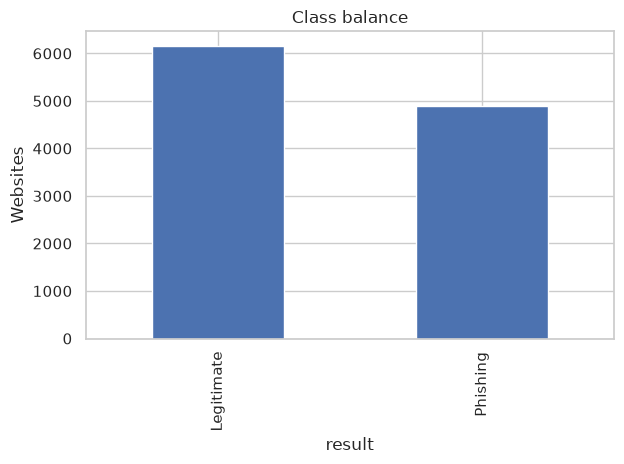

In [5]:
print("Rows:", len(X), "| Features:", X.shape[1])
print("Missing cells:", int(X.isna().sum().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))
display(X.describe().T)
y.value_counts().rename(index={0:"Legitimate", 1:"Phishing"}).plot(kind="bar", title="Class balance")
plt.ylabel("Websites"); plt.tight_layout(); plt.show()

## Splitting and Traing the models

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Phishing share — train:", round(y_train.mean(), 4), "test:", round(y_test.mean(), 4))

Train: (8844, 25) Test: (2211, 25)
Phishing share — train: 0.443 test: 0.4432


## Using Hyperparameter tunning and RandomSearchCV for best results

In [8]:
def make_models_and_spaces():
    models = {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=3000, class_weight="balanced",
                                         random_state=RANDOM_STATE))
        ]),
        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("model", DecisionTreeClassifier(class_weight="balanced",
                                              random_state=RANDOM_STATE))
        ]),
        "KNN": Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        "Naive Bayes": Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("scaler", StandardScaler()),
            ("model", GaussianNB())
        ]),
        "SVM": Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("scaler", StandardScaler()),
            ("model", SVC(probability=True, class_weight="balanced",
                          random_state=RANDOM_STATE))
        ])
    }
    spaces = {
        "Logistic Regression": {
            "model__C": loguniform(1e-3, 1e2),
            "model__solver": ["liblinear", "lbfgs"]
        },
        "Decision Tree": {
            "model__criterion": ["gini", "entropy", "log_loss"],
            "model__max_depth": [None, 4, 6, 8, 10, 14, 18, 24, 32],
            "model__min_samples_split": randint(2, 30),
            "model__min_samples_leaf": randint(1, 15),
            "model__max_features": [None, "sqrt", "log2"]
        },
        "KNN": {
            "model__n_neighbors": randint(3, 40),
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        },
        "Naive Bayes": {
            "model__var_smoothing": loguniform(1e-12, 1e-6)
        },
        "SVM": {
            "model__C": loguniform(1e-2, 1e2),
            "model__kernel": ["rbf", "linear"],
            "model__gamma": ["scale", "auto"]
        }
    }
    return models, spaces

def evaluate(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "AUC": roc_auc_score(y_eval, prob),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1 Score": f1_score(y_eval, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_eval, pred)
    }

In [9]:
models, search_spaces = make_models_and_spaces()
searches, best_models, search_rows = {}, {}, []

for name, estimator in models.items():
    print(f"Optimizing {name} ...", flush=True)
    started = time.time()
    search = RandomizedSearchCV(
        estimator, search_spaces[name], n_iter=N_ITER, scoring="f1",
        cv=cv, n_jobs=-1, random_state=RANDOM_STATE, refit=True,
        return_train_score=False
    )
    search.fit(X_train, y_train)
    searches[name] = search
    best_models[name] = search.best_estimator_
    search_rows.append({
        "Model": name, "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_,
        "Search seconds": round(time.time() - started, 1)
    })
    print(f"  Best CV F1={search.best_score_:.4f}; elapsed={time.time()-started:.1f}s")

search_results = pd.DataFrame(search_rows).sort_values("Best CV F1", ascending=False)
display(search_results)

Optimizing Logistic Regression ...
  Best CV F1=0.9133; elapsed=7.3s
Optimizing Decision Tree ...
  Best CV F1=0.9304; elapsed=3.0s
Optimizing KNN ...
  Best CV F1=0.9362; elapsed=13.9s
Optimizing Naive Bayes ...
  Best CV F1=0.7233; elapsed=3.0s
Optimizing SVM ...
  Best CV F1=0.9395; elapsed=1151.1s


,Model,Best CV F1,Best Parameters,Search seconds
4,SVM,0.939459,"{'model__C': 8.471801418819979, 'model__gamma'...",1151.1
2,KNN,0.936191,"{'model__n_neighbors': 24, 'model__p': 1, 'mod...",13.9
1,Decision Tree,0.930419,"{'model__criterion': 'log_loss', 'model__max_d...",3.0
0,Logistic Regression,0.913268,"{'model__C': 0.0019517224641449498, 'model__so...",7.3
3,Naive Bayes,0.723310,{'model__var_smoothing': 6.598711072054075e-07},3.0


## Model Results

In [10]:
results = pd.DataFrame([
    {"Model": name, **evaluate(model, X_test, y_test)}
    for name, model in best_models.items()
]).sort_values(["F1 Score", "MCC"], ascending=False).reset_index(drop=True)
display(results.style.format({c:"{:.4f}" for c in METRICS}))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,SVM,0.9502,0.9861,0.9494,0.9378,0.9435,0.8991
1,KNN,0.9439,0.9862,0.9573,0.9143,0.9353,0.8866
2,Decision Tree,0.9367,0.9813,0.9260,0.9316,0.9288,0.8718
3,Logistic Regression,0.9199,0.9690,0.9213,0.8959,0.9084,0.8376
4,Naive Bayes,0.6793,0.9618,0.5805,0.9969,0.7338,0.4934


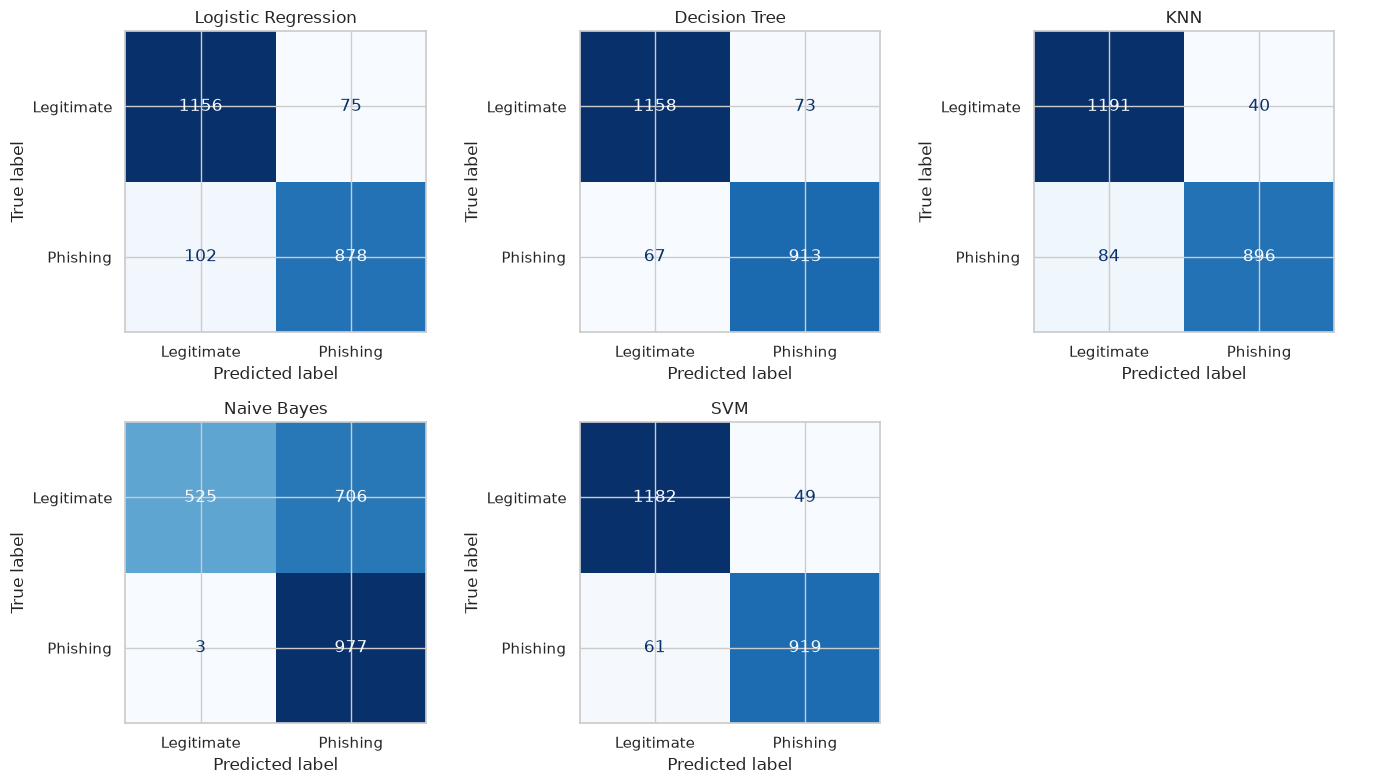

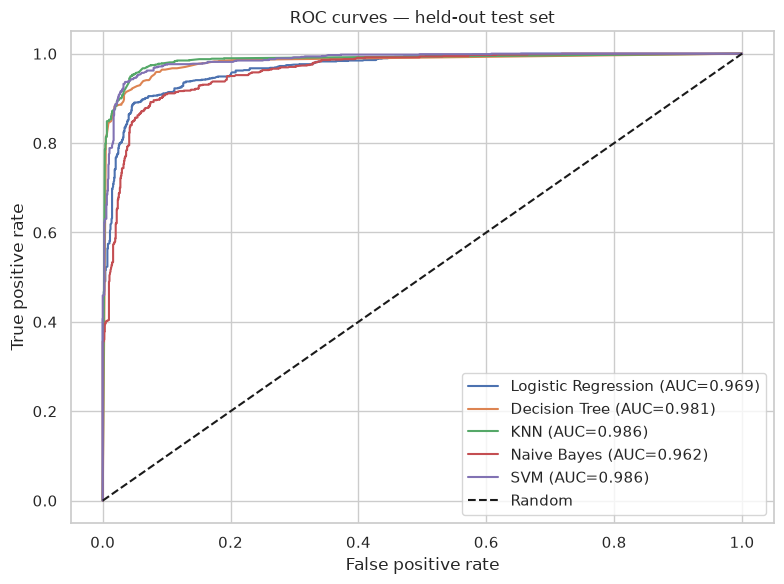

In [11]:
## Confusion MAtrix and ROC Curve

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, model) in zip(axes.flat, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["Legitimate", "Phishing"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
for ax in axes.flat[len(best_models):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
for name, model in best_models.items():
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],"k--",label="Random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves — held-out test set"); plt.legend(); plt.tight_layout(); plt.show()

## Selecting Best Model

#### Based on F1 Score

In [12]:
best_name = results.iloc[0]["Model"]
best_model = best_models[best_name]
print("Selected model:", best_name)
print("Metrics:", results.iloc[0][METRICS].to_dict())
print("\nClassification report:")
print(classification_report(y_test, best_model.predict(X_test),
                            target_names=["Legitimate", "Phishing"], zero_division=0))

Selected model: SVM
Metrics: {'Accuracy': 0.9502487562189055, 'AUC': 0.9860500008289261, 'Precision': 0.9493801652892562, 'Recall': 0.9377551020408164, 'F1 Score': 0.9435318275154004, 'MCC': 0.8991269346812871}

Classification report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.96      0.96      1231
    Phishing       0.95      0.94      0.94       980

    accuracy                           0.95      2211
   macro avg       0.95      0.95      0.95      2211
weighted avg       0.95      0.95      0.95      2211



## Saving All models in artifacts. 

In [13]:
artifact_dir = "artifacts"
os.makedirs(artifact_dir, exist_ok=True)

# Store every optimized model with a self-describing deployment bundle.
for name, model in best_models.items():
    metrics = results.set_index("Model").loc[name, METRICS].to_dict()
    bundle = {
        "model": model,
        "name": name,
        "features": list(ALL_LIVE_FEATURES),
        "metrics": {k: float(v) for k, v in metrics.items()},
        "positive_class": 1,
        "target_mapping": {"0": "Legitimate", "1": "Phishing"},
        "feature_value_mapping": {"1": "legitimate-like", "0": "suspicious", "-1": "phishing-like"}
    }
    filename = name.lower().replace(" ", "_") + "_tuned.joblib"
    joblib.dump(bundle, os.path.join(artifact_dir, filename))

best_row = results.iloc[0]
with open(os.path.join(artifact_dir, "best_model.json"), "w") as f:
    json.dump({
        "model": best_name,
        "best_params": {k: str(v) for k, v in searches[best_name].best_params_.items()},
        "test_metrics": {k: float(best_row[k]) for k in METRICS},
        "features": ALL_LIVE_FEATURES,
        "target_mapping": {"0": "Legitimate", "1": "Phishing"}
    }, f, indent=2)

with open(os.path.join(artifact_dir, "feature_schema.json"), "w") as f:
    json.dump({
        "features": ALL_LIVE_FEATURES,
        "excluded_features": UNAVAILABLE,
        "target_mapping": {"0": "Legitimate", "1": "Phishing"},
        "feature_value_mapping": {"1": "legitimate-like", "0": "suspicious", "-1": "phishing-like"},
        "dataset": "UCI Phishing Websites (id=327)"
    }, f, indent=2)

results.to_csv(os.path.join(artifact_dir, "tuned_results.csv"), index=False)
search_results.to_csv(os.path.join(artifact_dir, "search_results.csv"), index=False)
print("Saved artifacts:", sorted(os.listdir(artifact_dir)))

Saved artifacts: ['best_model.json', 'decision_tree_tuned.joblib', 'feature_schema.json', 'knn_tuned.joblib', 'logistic_regression_tuned.joblib', 'naive_bayes_tuned.joblib', 'search_results.csv', 'svm_tuned.joblib', 'tuned_results.csv']


## Predictions on Actual url 

In [14]:
from pathlib import Path
import phishing_checker as pc

def check_live_url(url, model_name=best_name):
    model_file = Path("artifacts") / (model_name.lower().replace(" ", "_") + "_tuned.joblib")
    live_bundle = pc.load_model(model_file)
    report = pc.analyse(url, live_bundle)
    print("URL:", report["url"])
    print("Model:", live_bundle["name"])
    print("Verdict:", report["verdict"])
    if report["phishing_probability"] is not None:
        print(f"Phishing probability: {report['phishing_probability']:.1%}")
    print("Unavailable live features:", len(report["unavailable_features"]))
    if report["red_flags"]:
        print("\nWarning signals:")
        for flag in report["red_flags"]:
            print(f"- {flag['feature']}: {flag['meaning']} (value={flag['value']})")
    return report

# Paste a URL below, then run this cell. Leave blank to skip live analysis.
url_to_check = "https://paypal-security-update-account-login.com/index.html"
if url_to_check.strip():
    live_result = check_live_url(url_to_check)
else:
    print("Ready. Set url_to_check to a URL when you want to run a live check.")


URL: https://paypal-security-update-account-login.com/index.html
Model: SVM
Verdict: INCONCLUSIVE
Phishing probability: 6.0%
Unavailable live features: 15

Warning signals:
- URL_Length: URL is unusually long (value=0)
- Prefix_Suffix: domain name contains '-' (common in look-alike domains) (value=-1)
- DNSRecord: domain has no DNS record (value=-1)


In [17]:
## Testing on list of Urls

test_links = [
    "https://www.google.com",
    "https://www.microsoft.com",
    "https://www.wikipedia.org",
    "https://www.github.com",
    "https://www.python.org",
    "https://www.mozilla.org",
    "https://www.apple.com",
    "http://example.com/login",
    "https://example.com/account/verify",
    "https://example.com/login?verify=account",
    "http://example.com/update-account",
    "https://example.com/security/confirm-login",
    "http://example.com/secure/login?session=12345",
    "https://example.com/account/password-reset",
    "http://login-google.example.com/verify",
    "http://paypal-security.example.com/login",
    "http://microsoft-login.example.com/verify-account",
    "http://secure-bank-login.example.com/update",
    "http://appleid-verify.example.com/login",
    "http://account-security.example.com/confirm?password=reset"
]

for i in test_links:
    url_to_check = i
    if url_to_check.strip():
        live_result = check_live_url(url_to_check)
        print("------------------------------------")
    else:
        print("Ready. Set url_to_check to a URL when you want to run a live check.")

URL: https://www.google.com
Model: SVM
Verdict: LEGITIMATE
Phishing probability: 1.5%
Unavailable live features: 0
------------------------------------
URL: https://www.microsoft.com
Model: SVM
Verdict: PHISHING
Phishing probability: 1.0%
Unavailable live features: 0

Warning signals:
- Domain_registeration_length: domain registration expires within a year (value=-1)
- Request_URL: many images/media are loaded from other domains (value=-1)
- Links_in_tags: many script/meta/link resources come from other domains (value=0)
------------------------------------
URL: https://www.wikipedia.org
Model: SVM
Verdict: PHISHING
Phishing probability: 1.0%
Unavailable live features: 0

Warning signals:
- Domain_registeration_length: domain registration expires within a year (value=-1)
- Request_URL: many images/media are loaded from other domains (value=-1)
- Links_in_tags: many script/meta/link resources come from other domains (value=0)
------------------------------------
URL: https://www.github.